# 03 — Modeling and Evaluation


Goals:
- Establish a majority-class baseline
- Train candidate models
- Use consistent preprocessing and splits
- Compare classification metrics
- Add cross-validation and tuning


## Baseline Classification

Before comparing machine learning models, we establish a naive baseline.

Because the target is imbalanced, the baseline classifier predicts the
most frequent class for every observation.

Future models should be compared against this baseline rather than
considering accuracy in isolation.

## Load the data

In [52]:
import sys
from pathlib import Path

import pandas as pd

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split

from sklearn.pipeline import Pipeline


CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR
sys.path.append(str(PROJECT_ROOT))

from src.evaluation import (
    evaluate_binary_classifier,
    get_confusion_matrix,
    results_to_dataframe,
    plot_confusion_matrix,
    plot_roc_curve,
    cross_validate_classifier,
    cross_validation_results_to_dataframe,
)

from src.preprocessing import build_preprocessor
from src.models import get_student3_models

DATA_PATH = PROJECT_ROOT / "data" / "bank-full.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. "
        "Download bank-full.csv and place it in the data/ folder."
    )

df = pd.read_csv(
    DATA_PATH,
    sep=";",
)




## Temporary Train/Test Split

In [53]:
df.head()

X = df.drop(columns=["y"])

y = df["y"].map({
    "no": 0,
    "yes": 1,
})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 36168
Testing observations: 9043


## Create a temporary baseline model

In [54]:
baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline.fit(
    X_train,
    y_train,
)

baseline_predictions = baseline.predict(
    X_test
)



## Evaluate the baseline model


In [55]:
baseline_probabilities = baseline.predict_proba(
    X_test
)[:, 1]


baseline_results = evaluate_binary_classifier(
    model_name="Majority Class Baseline",
    y_true=y_test,
    y_pred=baseline_predictions,
    y_score=baseline_probabilities,
)

baseline_results

{'model': 'Majority Class Baseline',
 'accuracy': 0.8830034280659074,
 'precision': 0.0,
 'recall': 0.0,
 'f1': 0.0,
 'roc_auc': 0.5}

## Comparison table

In [56]:
results = [
    baseline_results,
    qda_results,
    gnb_results,
]

results_df = results_to_dataframe(
    results
)

results_df

,model,accuracy,precision,recall,f1,roc_auc
0,Majority Class Baseline,0.883003,0.000000,0.000000,0.000000,0.50000
1,Quadratic Discriminant Analysis,0.870286,0.399299,0.215501,0.279926,0.74868
2,Gaussian Naive Bayes,0.848280,0.354898,0.362949,0.358879,0.73313


In [57]:
baseline_cm = get_confusion_matrix(
    y_test,
    baseline_predictions,
)

baseline_cm

array([[7985,    0],
       [1058,    0]])

## Cross-Validation Evaluation

Use stratified cross-validation to measure how consistently the baseline
model performs across multiple folds of the training data.

In [58]:
baseline_cv_results = cross_validate_classifier(
    model_name="Majority Class Baseline",
    estimator=baseline,
    X=X_train,
    y=y_train,
    cv=5,
)

baseline_cv_results

{'model': 'Majority Class Baseline',
 'accuracy_mean': np.float64(0.8830181385725526),
 'accuracy_std': np.float64(5.256047063157839e-05),
 'precision_mean': np.float64(0.0),
 'precision_std': np.float64(0.0),
 'recall_mean': np.float64(0.0),
 'recall_std': np.float64(0.0),
 'f1_mean': np.float64(0.0),
 'f1_std': np.float64(0.0),
 'roc_auc_mean': np.float64(0.5),
 'roc_auc_std': np.float64(0.0)}

In [59]:
cv_results = [
    baseline_cv_results
]

cv_results_df = cross_validation_results_to_dataframe(
    cv_results
)

cv_results_df

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Majority Class Baseline,0.883018,0.000053,0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.0


## Confusion Matrix Visualization

The confusion matrix shows how many observations are classified correctly
and incorrectly for each target class.

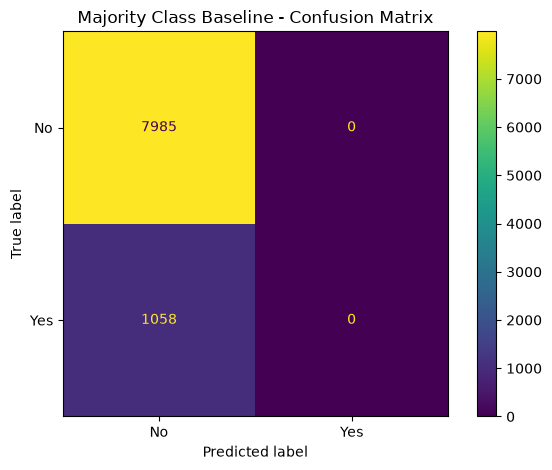

In [60]:
plot_confusion_matrix(
    y_true=y_test,
    y_pred=baseline_predictions,
    model_name="Majority Class Baseline",
)

## Evaluate baseline with ROC-AUC

In [61]:
baseline_results = evaluate_binary_classifier(
    model_name="Majority Class Baseline",
    y_true=y_test,
    y_pred=baseline_predictions,
    y_score=baseline_probabilities,
)

baseline_results

{'model': 'Majority Class Baseline',
 'accuracy': 0.8830034280659074,
 'precision': 0.0,
 'recall': 0.0,
 'f1': 0.0,
 'roc_auc': 0.5}

## ROC Curve

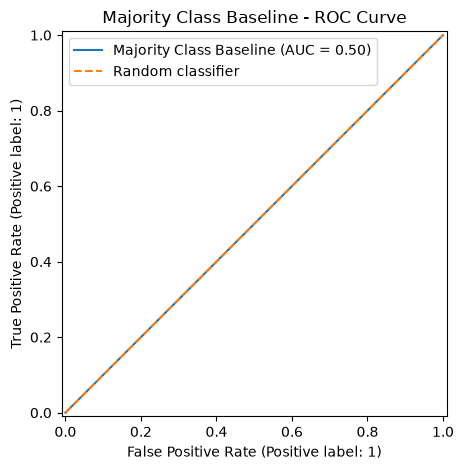

In [62]:
plot_roc_curve(
    y_true=y_test,
    y_score=baseline_probabilities,
    model_name="Majority Class Baseline",
)

## QDA and Gaussian Naive Bayes

The following models use the shared preprocessing framework.

Because QDA and Gaussian Naive Bayes require dense numerical input,
one-hot encoding is configured to produce a dense transformed matrix.

The current predictor set follows the preliminary preprocessing workflow
and may be updated after the final feature/leakage analysis.

In [63]:
numeric_features = [
    "age",
    "balance",
    "campaign",
    "previous",
]

categorical_features = [
    "job",
    "marital",
    "education",
    "housing",
    "loan",
    "contact",
    "month",
]

In [64]:
model_features = (
    numeric_features
    + categorical_features
)

X_model = X[model_features]

In [65]:
X_train_model, X_test_model, y_train_model, y_test_model = (
    train_test_split(
        X_model,
        y,
        test_size=0.20,
        stratify=y,
        random_state=42,
    )
)

In [66]:
student3_models = get_student3_models()

qda_model = student3_models[
    "Quadratic Discriminant Analysis"
]

In [67]:
qda_preprocessor = build_preprocessor(
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    dense_output=True,
    drop_first=True,
)

In [68]:
qda_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            qda_preprocessor,
        ),
        (
            "classifier",
            qda_model,
        ),
    ]
)
qda_pipeline.fit(
    X_train_model,
    y_train_model,
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['age','balance','campaign',...,'loan','contact','month']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, a

QDA initially failed because the one-hot encoded feature matrix produced
collinear predictors, causing the class covariance matrix to be rank-deficient.

To stabilize covariance estimation, QDA was regularized using `reg_param`.

In [69]:
qda_predictions = qda_pipeline.predict(
    X_test_model
)

qda_probabilities = qda_pipeline.predict_proba(
    X_test_model
)[:, 1]

In [70]:
qda_results = evaluate_binary_classifier(
    model_name="Quadratic Discriminant Analysis",
    y_true=y_test_model,
    y_pred=qda_predictions,
    y_score=qda_probabilities,
)

qda_results

{'model': 'Quadratic Discriminant Analysis',
 'accuracy': 0.870286409377419,
 'precision': 0.39929947460595444,
 'recall': 0.21550094517958412,
 'f1': 0.27992633517495397,
 'roc_auc': 0.7486802996639493}

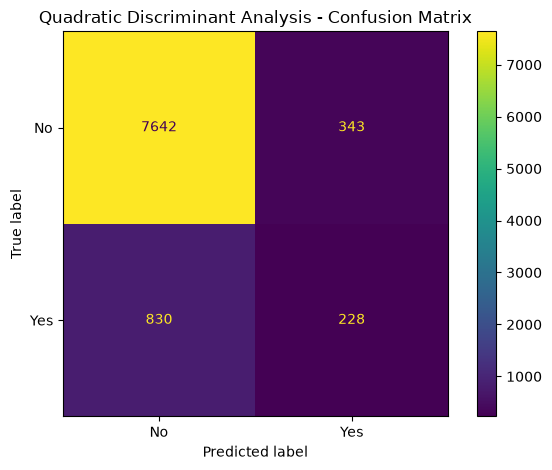

In [71]:
plot_confusion_matrix(
    y_true=y_test_model,
    y_pred=qda_predictions,
    model_name="Quadratic Discriminant Analysis",
)

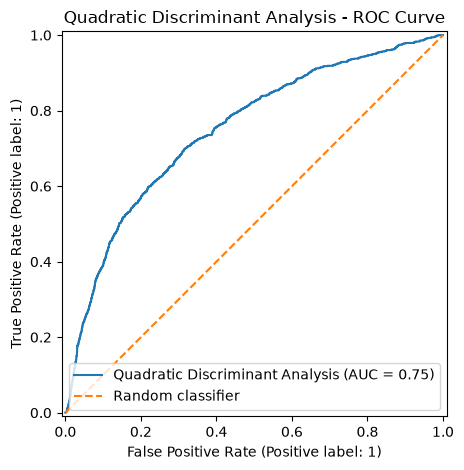

In [72]:
plot_roc_curve(
    y_true=y_test_model,
    y_score=qda_probabilities,
    model_name="Quadratic Discriminant Analysis",
)

In [73]:
qda_cv_results = cross_validate_classifier(
    model_name="Quadratic Discriminant Analysis",
    estimator=qda_pipeline,
    X=X_train_model,
    y=y_train_model,
    cv=5,
)

qda_cv_results

{'model': 'Quadratic Discriminant Analysis',
 'accuracy_mean': np.float64(0.8698298788067056),
 'accuracy_std': np.float64(0.0034065368429061576),
 'precision_mean': np.float64(0.3991579922381191),
 'precision_std': np.float64(0.022177453178428973),
 'recall_mean': np.float64(0.2207546590525314),
 'recall_std': np.float64(0.013048733712732229),
 'f1_mean': np.float64(0.2839731344938207),
 'f1_std': np.float64(0.01333460613173467),
 'roc_auc_mean': np.float64(0.7398130580531597),
 'roc_auc_std': np.float64(0.003361638646837198)}

In [74]:
gnb_preprocessor = build_preprocessor(
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    dense_output=True,
)

In [75]:
gnb_model = student3_models[
    "Gaussian Naive Bayes"
]

In [76]:
gnb_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            gnb_preprocessor,
        ),
        (
            "classifier",
            gnb_model,
        ),
    ]
)

In [77]:
gnb_pipeline.fit(
    X_train_model,
    y_train_model,
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['age','balance','campaign',...,'loan','contact','month']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, a

In [78]:
gnb_predictions = gnb_pipeline.predict(
    X_test_model
)

gnb_probabilities = gnb_pipeline.predict_proba(
    X_test_model
)[:, 1]

In [79]:
gnb_results = evaluate_binary_classifier(
    model_name="Gaussian Naive Bayes",
    y_true=y_test_model,
    y_pred=gnb_predictions,
    y_score=gnb_probabilities,
)

gnb_results

{'model': 'Gaussian Naive Bayes',
 'accuracy': 0.848280437907774,
 'precision': 0.35489833641404805,
 'recall': 0.3629489603024575,
 'f1': 0.35887850467289717,
 'roc_auc': 0.733130467926038}

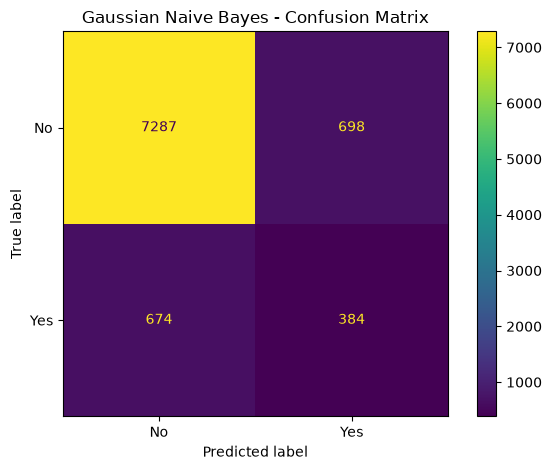

In [80]:
plot_confusion_matrix(
    y_true=y_test_model,
    y_pred=gnb_predictions,
    model_name="Gaussian Naive Bayes",
)

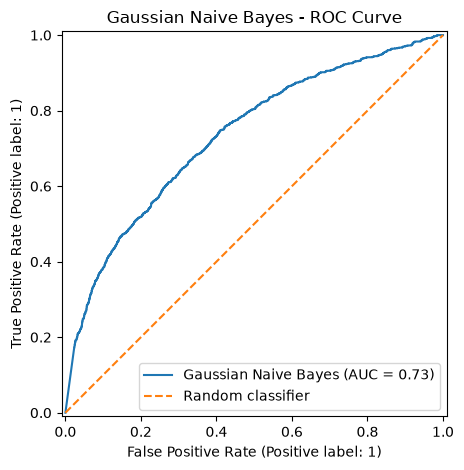

In [81]:
plot_roc_curve(
    y_true=y_test_model,
    y_score=gnb_probabilities,
    model_name="Gaussian Naive Bayes",
)

In [82]:
gnb_cv_results = cross_validate_classifier(
    model_name="Gaussian Naive Bayes",
    estimator=gnb_pipeline,
    X=X_train_model,
    y=y_train_model,
    cv=5,
)

gnb_cv_results

{'model': 'Gaussian Naive Bayes',
 'accuracy_mean': np.float64(0.8440057188810799),
 'accuracy_std': np.float64(0.0018952249379325747),
 'precision_mean': np.float64(0.3428198066604763),
 'precision_std': np.float64(0.0067949081898354335),
 'recall_mean': np.float64(0.3637457749643437),
 'recall_std': np.float64(0.012506492109980888),
 'f1_mean': np.float64(0.35291239952481473),
 'f1_std': np.float64(0.008717489075871622),
 'roc_auc_mean': np.float64(0.7211456976574707),
 'roc_auc_std': np.float64(0.0038198404911935647)}

In [83]:
cv_results = [
    baseline_cv_results,
    qda_cv_results,
    gnb_cv_results,
]

cv_results_df = (
    cross_validation_results_to_dataframe(
        cv_results
    )
)

cv_results_df

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Majority Class Baseline,0.883018,0.000053,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000
1,Quadratic Discriminant Analysis,0.869830,0.003407,0.399158,0.022177,0.220755,0.013049,0.283973,0.013335,0.739813,0.003362
2,Gaussian Naive Bayes,0.844006,0.001895,0.342820,0.006795,0.363746,0.012506,0.352912,0.008717,0.721146,0.003820
